In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Image, display

from data_analysis.config import load_config

In [4]:
cfg = load_config()
tables, figs = cfg["paths"]["tables"], cfg["paths"]["figures"]

gate = json.loads((tables / "hahn_positive_control_gate.json").read_text())
hahn_slopes = pd.read_csv(tables / "table_hahn_cas_slopes.csv")
stats = pd.read_csv(tables / "table_walker_cas_stats.csv")
scores = pd.read_csv(tables / "walker_cas_scores.csv")
gate["checks"]

{'all_slopes_positive_fdr': True,
 'all_spearman_positive_fdr': True,
 'cc_tied_with_fastest': True,
 'cp_rank_le_7': True,
 'cer_rank_le_7': True}

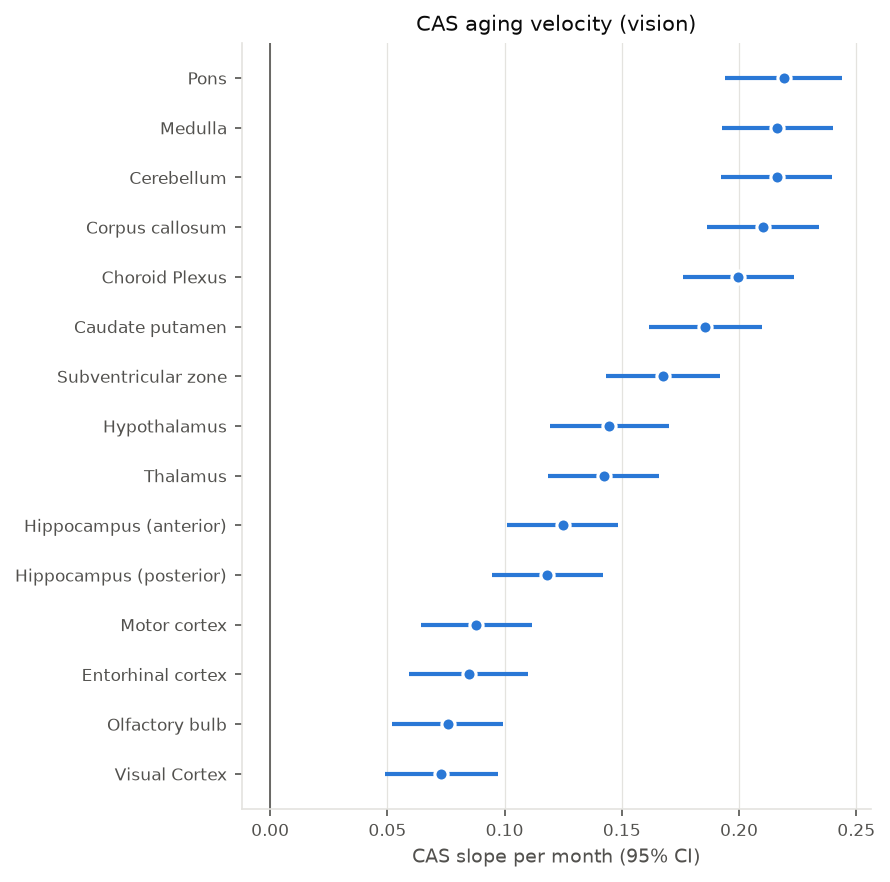

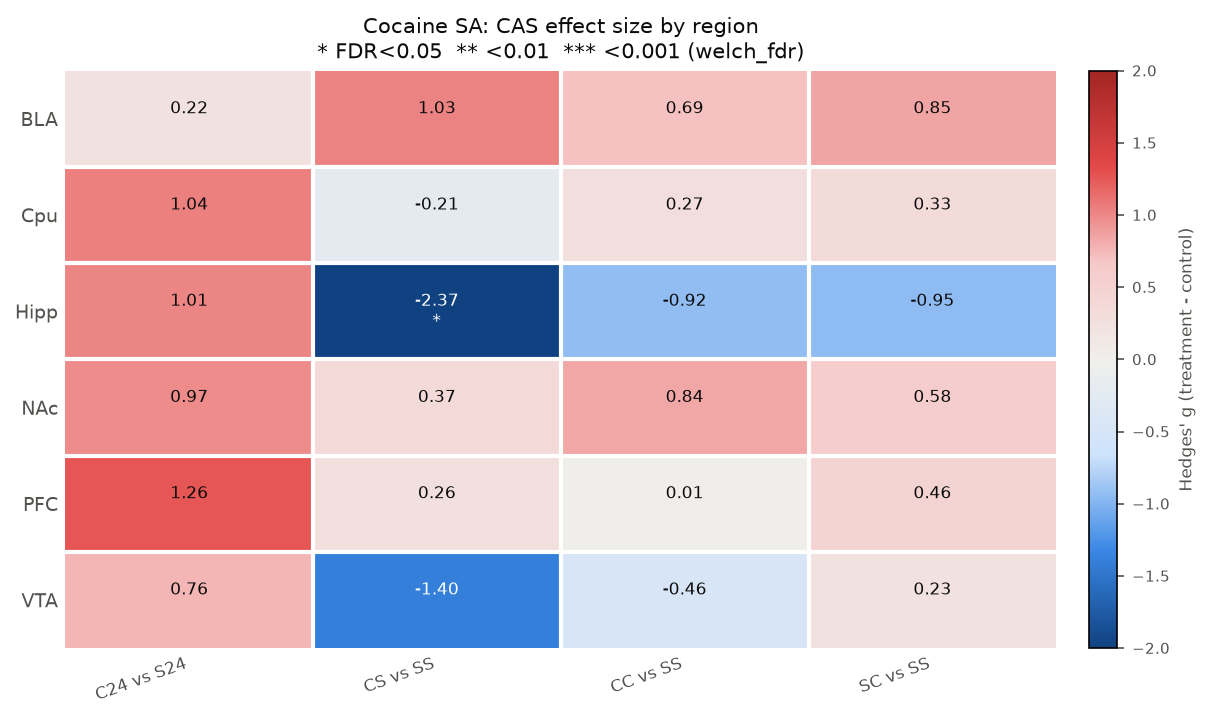

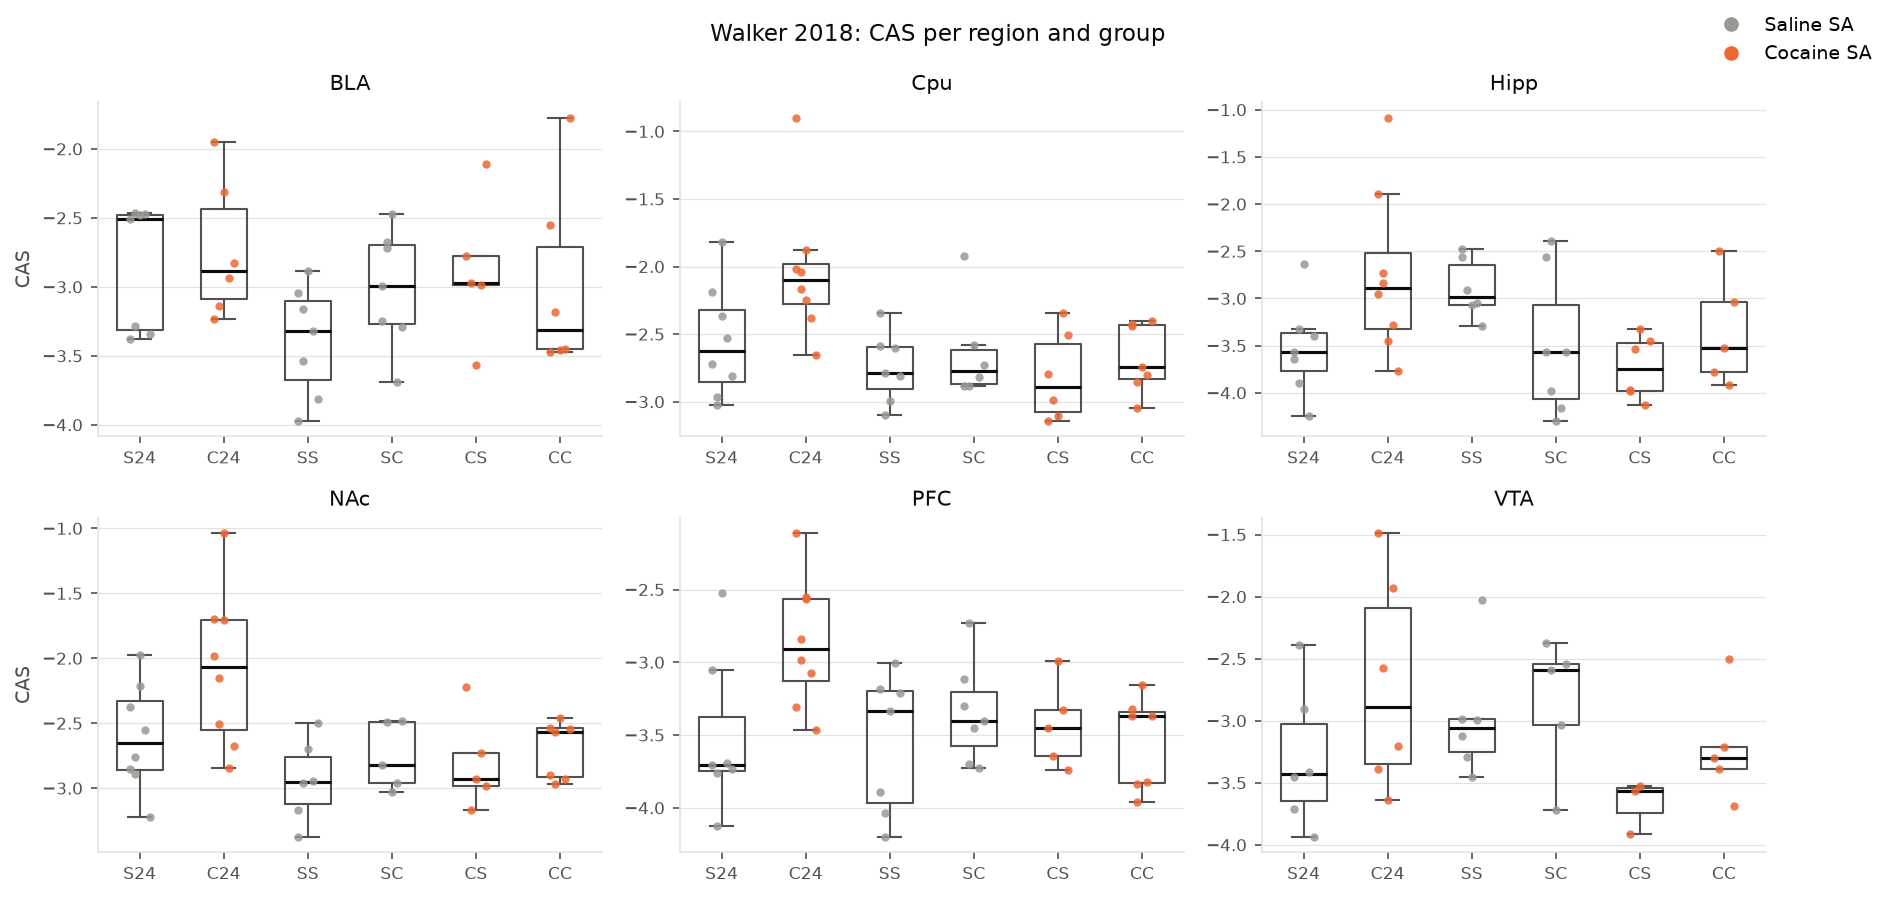

In [5]:
for name in ["fig1b_hahn_cas_slopes.png", "fig2_walker_cas_heatmap.png", "fig3_walker_cas_boxplots.png"]:
    display(Image(figs / name))

In [6]:
stats.pivot(index="region", columns="comparison", values="g").round(2)

comparison,C24 vs S24,CC vs SS,CS vs SS,SC vs SS
region,,,,
BLA,0.22,0.69,1.03,0.85
Cpu,1.04,0.27,-0.21,0.33
Hipp,1.01,-0.92,-2.37,-0.95
NAc,0.97,0.84,0.37,0.58
PFC,1.26,0.01,0.26,0.46
VTA,0.76,-0.46,-1.40,0.23


In [7]:
stats[["region", "comparison", "g", "g_ci_low", "g_ci_high", "welch_fdr", "perm_fdr"]].round(3)

,region,comparison,g,g_ci_low,g_ci_high,welch_fdr,perm_fdr
0,BLA,C24 vs S24,0.219,-0.871,1.410,0.726,0.737
1,BLA,CS vs SS,1.029,0.086,2.415,0.305,0.260
2,BLA,CC vs SS,0.689,-0.405,1.657,0.440,0.343
3,BLA,SC vs SS,0.852,-0.031,2.080,0.305,0.278
4,Cpu,C24 vs S24,1.045,0.260,2.332,0.244,0.260
5,Cpu,CS vs SS,-0.213,-1.609,0.788,0.726,0.737
6,Cpu,CC vs SS,0.267,-0.721,1.500,0.726,0.737
7,Cpu,SC vs SS,0.329,-0.948,1.271,0.726,0.618
8,Hipp,C24 vs S24,1.008,0.278,2.086,0.244,0.248
9,Hipp,CS vs SS,-2.373,-4.290,-1.711,0.030,0.096


In [8]:
scores.groupby(["region", "group"])["cas"].mean().unstack().round(2)[["S24", "SS"]]

group,S24,SS
region,,
BLA,-2.85,-3.39
Cpu,-2.55,-2.75
Hipp,-3.53,-2.89
NAc,-2.60,-2.94
PFC,-3.51,-3.55
VTA,-3.30,-2.98


Text(0.5, 1.0, 'CAS trajectories: corpus callosum, caudate putamen, visual cortex')

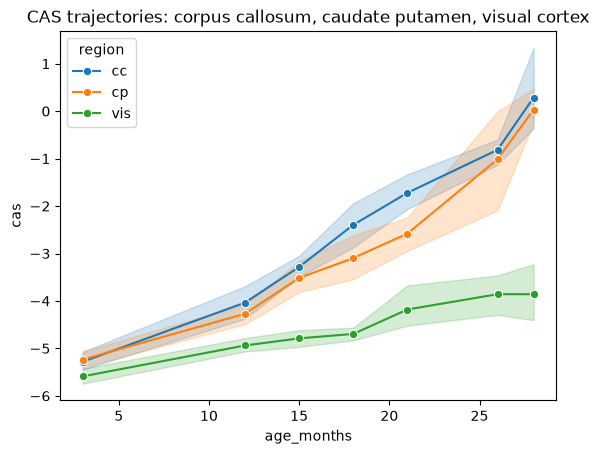

In [9]:
hahn = pd.read_csv(tables / "hahn_cas_scores.csv").query("method == 'vision'")
sns.lineplot(data=hahn[hahn["region"].isin(["cc", "cp", "vis"])],
             x="age_months", y="cas", hue="region", marker="o")
plt.title("CAS trajectories: corpus callosum, caudate putamen, visual cortex")

In [10]:
z = pd.read_csv(tables / "table_hahn_cas_slopes_zscore.csv")[["region", "slope"]]
v = hahn_slopes[["region", "slope"]]
v.merge(z, on="region", suffixes=("_vision", "_zscore")).sort_values("slope_vision", ascending=False)

,region,slope_vision,slope_zscore
0,pon,0.218962,0.162376
1,med,0.216215,0.174935
2,cer,0.216086,0.178648
3,cc,0.210159,0.187841
4,plx,0.199633,0.180017
5,cp,0.185647,0.169970
6,svz,0.167529,0.158421
7,hy,0.144621,0.160020
8,th,0.142184,0.171397
9,hi,0.124780,0.171267
